# Exercise: 7.3.1: Plug-and-Play methods

In this exercise we will us PnP methods for image debluring.

## Change runtime type and install DeepInverse package
First, we install the deepinverse library. Remeber to change the runtime of this notebook select ``Runtime`` -> ``Change runtime type`` and pick an available hardware accelerator.

In [1]:
!pip install git+https://github.com/deepinv/deepinv.git#egg=deepinv

  Cloning https://github.com/deepinv/deepinv.git to /tmp/pip-install-lkkfilj7/deepinv_fca58fc77f7942a486434b9c1f340422
  Running command git clone --filter=blob:none --quiet https://github.com/deepinv/deepinv.git /tmp/pip-install-lkkfilj7/deepinv_fca58fc77f7942a486434b9c1f340422
  Resolved https://github.com/deepinv/deepinv.git to commit 914d39ed80449858b6a14b94a5932250553ea46b
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for deepinv: filename=deepinv-0.3.7-py3-none-any.whl size=868930 sha256=380bdd835ee2a0dbb8715ce6b83a6ea1ba31d010a8e3f85d5223b0196c6fada0
  Stored in directory: /tmp/pip-ephem-wheel-cache-4xw17odj/wheels/bd/db/70/98ddf35b215d011d0885ad7fe69f70a379d288f5250cc8471a
Successfully built deepinv
  Attempting uninstall: deepinv
    Found existing installation: deepinv 0.3.5
    Uninstalling deepinv-0.3.5:
      Successfully uninstalled deepinv-0.3.5


In [1]:
import deepinv as dinv
from torch.utils.data import DataLoader
import torch
from pathlib import Path
from torchvision import transforms
from deepinv.utils.demo import load_dataset, load_degradation
from deepinv.optim.prior import PnP
from deepinv.optim.data_fidelity import L2
from deepinv.optim.optimizers import optim_builder
from deepinv.training import test
import numpy as np

import matplotlib.pyplot as plt
from timeit import default_timer as timer

In [2]:
BASE_DIR = Path(".")
DATA_DIR = BASE_DIR / "measurements"
DEG_DIR = BASE_DIR / "degradations"

method = "PnP"

In [3]:
torch.cuda.is_available()

torch.manual_seed(0)
device = dinv.utils.get_freer_gpu() if torch.cuda.is_available() else "cpu"

Selected GPU 0 with 7876.4375 MiB free memory


# Testing of the trained denoisers with PnP-ADMM-alt algorithm

As a test problem, we will condsider downsampling and blurring combined together.  

In [4]:
operation = "downsampled_deblurring"
train_dataset_name = "CBSD68"
test_dataset_name = "set3c"

img_size = 64 if torch.cuda.is_available() else 32

test_transform = transforms.Compose(
    [transforms.CenterCrop(img_size), transforms.ToTensor()]
)

val_dataset = load_dataset(train_dataset_name, test_transform) 
test_dataset = load_dataset(test_dataset_name, test_transform)

# Select 4 validation images
indices = torch.randperm(len(val_dataset))
n_val_images = 4
val_dataset = torch.utils.data.Subset(val_dataset, indices[-n_val_images:])

In [5]:
# Generate the degradation operator.
kernel_index = 1
kernel_torch = load_degradation(
    "kernels_12.npy", DEG_DIR / "kernels", index=kernel_index
)
kernel_torch = kernel_torch.unsqueeze(0).unsqueeze(
    0
)  # add batch and channel dimensions

# Use parallel dataloader if using a GPU to fasten training, otherwise, as all computes are on CPU, use synchronous dataloading.
num_workers = 1 if torch.cuda.is_available() else 0

factor = 2  # down-sampling factor
n_channels = 3  # 3 for color images, 1 for gray-scale images
n_test_images = 3 # Maximal number of images to restore from the input dataset
noise_level_img = 0.03  # Gaussian Noise standart deviation for the degradation

physics = dinv.physics.Downsampling(
    img_size=(n_channels, img_size, img_size),
    factor=factor,
    filter=kernel_torch,
    device=device,
    noise_model=dinv.physics.GaussianNoise(sigma=noise_level_img),
)


# Generate a dataset in a HDF5 folder in "{dir}/dinv_dataset0.h5'" and load it.
DATASET_DIR = 'my_pnp_dataset'
measurement_dir = DATA_DIR / DATASET_DIR / operation
dinv_dataset_path = dinv.datasets.generate_dataset(
    train_dataset=val_dataset,
    test_dataset=test_dataset,
    physics=physics,
    device=device,
    save_dir=measurement_dir,
    train_datapoints=n_val_images,
    test_datapoints = n_test_images,
    num_workers=num_workers,
    overwrite_existing = True
)

val_dataset = dinv.datasets.HDF5Dataset(path=dinv_dataset_path, train=True)
test_dataset = dinv.datasets.HDF5Dataset(path=dinv_dataset_path, train=False)

val_dataloader = DataLoader(
      val_dataset, batch_size=1, num_workers=num_workers, shuffle=False
  )

test_dataloader = DataLoader(
      test_dataset, batch_size=1, num_workers=num_workers, shuffle=False
  )

/homes/numerik/melnyk/scratch/anaconda3_new/lib/python3.13/site-packages/deepinv/datasets/datagenerator.py:344: UserWarning: Dataset measurements/my_pnp_dataset/downsampled_deblurring/dinv_dataset0.h5 already exists, this will close and overwrite the previous dataset.
  warn(


Dataset has been saved at measurements/my_pnp_dataset/downsampled_deblurring/dinv_dataset0.h5


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.06782916..1.0522804].


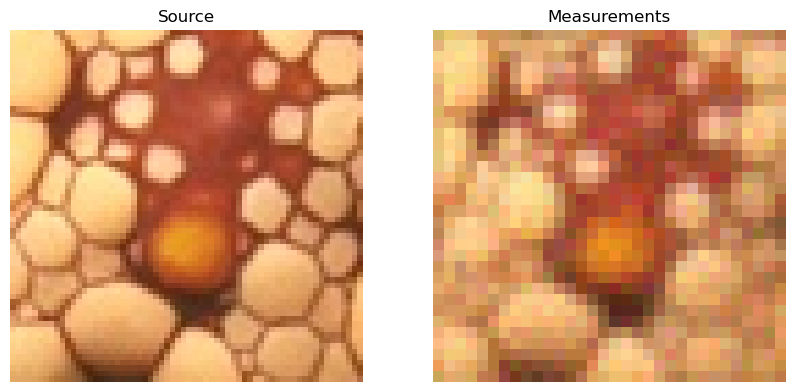

In [6]:
plt.subplots(1, 2, figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(test_dataset[2][0].permute(1, 2, 0))
plt.axis("off")
plt.title('Source')

plt.subplot(1, 2, 2)
plt.imshow(test_dataset[2][1].permute(1, 2, 0))
plt.axis("off")
plt.title('Measurements')

plt.show()

# Let us start by implementing ADMM algorithm with TV
DeepInverse provides a number of solvers for solving variational inverse problems. In particular, it include Gradient Descent (Algorithm 1) as `GD`, Forfard-Backfard Splitting (Algorithm 3) as `'PGD'` and ADMM (Algorithm 5) as `'ADMM'`. These algorithms are set up using `optim_builder` function, see respective [guide](https://deepinv.github.io/deepinv/user_guide/reconstruction/optimization.html#optim) and [documentation](https://deepinv.github.io/deepinv/api/stubs/deepinv.optim.optim_builder.html) for more details.

We typically work with functions of the form $f + g$, where $f$ is data fidelity and $g$ is regularizer. For ADMM, we need to provide a `data fidelity` as $f$ and `prior` as proximal mapping for $g$.
A number of [standard priors](https://deepinv.github.io/deepinv/user_guide/reconstruction/optimization.html#priors) are already implemented in the package. Each of the algorithms requires additional parameters. For ADMM, we need to provide three: `stepsize`, `lambda` and `beta`. Check out how ADMM iteration is defined and determize the values of the mentioned parameters in terms of $\alpha$ and $\gamma$ in Algorithm 5.  

Implement ADMM with TV prior for a given regularization parameter and test your implementation.

In [7]:
# Parameters of the algorithm to solve the inverse problem
early_stop = True  # Stop algorithm when convergence criteria is reached
backtracking = False
use_bicubic_init = False  # Use bicubic interpolation to initialize the algorithm
batch_size = 1  # batch size for evaluation is necessarily 1 for early stopping and backtracking to work.
max_iter = 500

# Select the data fidelity term
data_fidelity = L2()

def prepare_TV_model(reg):
    params_algo = {
                "stepsize": 1.0,
                "lambda": reg,
                "beta": 1.0,
                }

    model_tv = optim_builder(
        iteration="ADMM",
        prior=dinv.optim.prior.TVPrior(n_it_max=20), # Use TV prior with 20 subitertations
        data_fidelity=data_fidelity,
        early_stop=early_stop,
        max_iter=max_iter,
        verbose=False,
        params_algo=params_algo,
    )
    model_tv.eval()
    return model_tv

In [8]:
def plot_results(x,y,x_rec, label):
    plt.subplots(1, 3, figsize=(15, 5))
    plt.subplot(1, 3, 1)
    plt.imshow(x.cpu().permute(1, 2, 0))
    plt.axis("off")
    plt.title('Source')
    
    plt.subplot(1, 3, 2)
    plt.imshow(y.cpu().permute(1, 2, 0))
    plt.axis("off")
    plt.title('Measurements')
    
    plt.subplot(1, 3, 3)
    plt.imshow(x_rec[0].cpu().permute(1, 2, 0))
    plt.axis("off")
    plt.title(label)
    
    plt.show()

Let's test our ADMM algorithm

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.06782916..1.0522804].


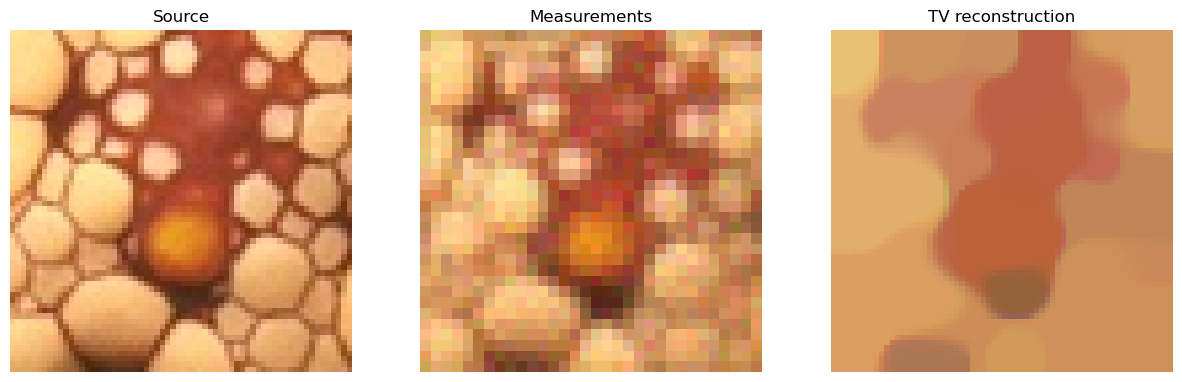

In [9]:
model_tv = prepare_TV_model(0.1)
x = test_dataset[2][0].to(device)
y = test_dataset[2][1].to(device)


x_tv = model_tv(
    y, physics, compute_metrics=False, x_gt=x
)

plot_results(x,y,x_tv, 'TV reconstruction')

# Perform parameter search for optimal performance
[Utility function test](https://deepinv.github.io/deepinv/api/stubs/deepinv.test.html) provides functionality to evaluate models on the datasets and compare the metrics.  
Use it to find the best parameter for regularization TV. 

In [10]:
def param_search(label, model_func, param_range):
    best_PSNR = -99
    best_par = param_range[0]
    best_ref = -1
    RESULTS_DIR = BASE_DIR / label

    # Select the best model on the validation set
    for ni in range(len(param_range)):
        par = param_range[ni]
        model = model_func(par)

        res = test(
          model=,
          test_dataloader=val_dataloader,
          physics=physics,
          device=device,
          plot_images=False,
          save_folder=RESULTS_DIR / method / operation / measurement_dir,
          plot_convergence_metrics=False,
          verbose=True,
          no_learning_method = "A_dagger",
        )
        print('Parameter:', par, ' PSNR: ', res["PSNR"])
        
        if res["PSNR"] > best_PSNR:
            best_PSNR = res["PSNR"]
            best_par = par

    # Use the best model on the test set
    model = model_func(best_par)
    RESULTS_DIR = BASE_DIR / label / 'best'

    best_res = test(
      model=model,
      test_dataloader=test_dataloader,
      physics=physics,
      device=device,
      plot_images=True,
      save_folder=RESULTS_DIR / method / operation / measurement_dir / 'best',
      plot_convergence_metrics=True,
      verbose=True,
      no_learning_method = "A_dagger"
    )
    
    print('Best: Paramereter: ', best_par, 'Test PSNR: ', best_res["PSNR"])
    return model, best_par, best_res["PSNR"]

/homes/numerik/melnyk/scratch/anaconda3_new/lib/python3.13/site-packages/deepinv/training/trainer.py:542: UserWarning: Update progress bar frequency of 1 may slow down training on GPU. Consider setting freq_update_progress_bar > 1.
  warnings.warn(
Test: 100%|█████████████████████████████████████████████| 4/4 [00:25<00:00,  6.30s/it, PSNR=22.4, PSNR no learning=15.9]

Test results:
PSNR no learning: 15.868 +- 0.241
PSNR: 22.378 +- 1.227
Parameter: 0.001  PSNR:  22.37816286087036



Test: 100%|███████████████████████████████████████████████| 4/4 [00:24<00:00,  6.21s/it, PSNR=23, PSNR no learning=15.9]

Test results:
PSNR no learning: 15.868 +- 0.241
PSNR: 22.969 +- 1.801
Parameter: 0.0031622776601683794  PSNR:  22.96917963027954



Test: 100%|█████████████████████████████████████████████| 4/4 [00:24<00:00,  6.05s/it, PSNR=22.2, PSNR no learning=15.9]

...


Test: 100%|█████████████████████████████████████████████| 4/4 [00:18<00:00,  4.56s/it, PSNR=20.8, PSNR no learning=15.9]

Test results:
PSNR no learning: 15.868 +- 0.241
PSNR: 20.810 +- 2.222
Parameter: 0.03162277660168379  PSNR:  20.810315132141113



Test: 100%|█████████████████████████████████████████████| 4/4 [00:13<00:00,  3.30s/it, PSNR=19.1, PSNR no learning=15.9]

Test results:
PSNR no learning: 15.868 +- 0.241
PSNR: 19.134 +- 2.238
Parameter: 0.1  PSNR:  19.13392162322998



Test:  67%|██████████████████████████████               | 2/3 [00:18<00:06,  6.15s/it, PSNR=24.3, PSNR no learning=16.2]

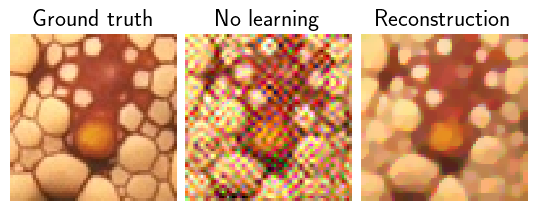

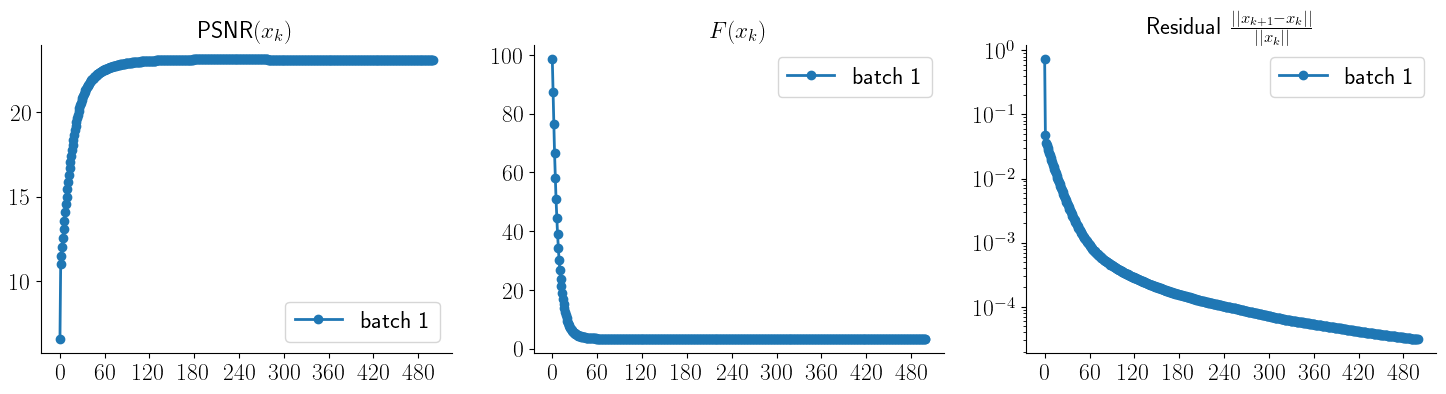

Test: 100%|█████████████████████████████████████████████| 3/3 [00:23<00:00,  7.78s/it, PSNR=24.3, PSNR no learning=16.2]

Test results:
PSNR no learning: 16.164 +- 0.215
PSNR: 24.316 +- 0.961
Best: Paramereter:  0.0031622776601683794 Test PSNR:  24.31620915730794


In [11]:
model_tv, reg_tv_best, tv_psnr = param_search('TV', prepare_TV_model, 10**np.arange(-3,-0.9,0.5))

# Next, we implement PnP-ADMM for a gradient step denoiser

To replace proximal map with denoiser, we can use [PnP class](https://deepinv.github.io/deepinv/api/stubs/deepinv.optim.PnP.html) as prior. Implement PnP-ADMM and PnP-ADMM-alt (Algorithms 7 and 8).

Recall that in PnP-ADMM, the undelying problem is
$$
\operatorname{arg}\min_{x} \frac{1}{2 \alpha} \|Ax - y\|_2^2 + R_\theta(x)
$$
Hence, parameters `"stepsize"` and `"lambda"` have to be defined acordingly. Furthermore, we need to provide denoiser strength $\sigma$ as an input. Investigate [the manual](https://deepinv.github.io/deepinv/user_guide/reconstruction/optimization.html#optimization-parameters) and find which parameter should be used.  

In [12]:
spec_norm = kernel_torch.sum().detach().item() # Why can compute the spectral norm of the undelying forward operator in this way?

def prepare_model_PnP(sigma,denoiser,admm_alt = False):
    alpha = 1.1 * spec_norm**2
        
    params_algo = {
            "stepsize": 1.0 / alpha,
            "g_param": sigma, # Noise level for the trained denoiser for PnP algorithms
            "lambda": alpha,
            "beta": 1.0,
            }
    prior = dinv.optim.PnP(denoiser)
    
    model = optim_builder(
        iteration="ADMM",
        prior=prior,
        data_fidelity=data_fidelity,
        early_stop=early_stop,
        max_iter=max_iter,
        verbose=False,
        params_algo=params_algo,
        g_first=admm_alt, # set True for PnP-ADMM-alt
    )
    model.eval()
    return model

Load the pretrained [GSDRUNet model](https://deepinv.github.io/deepinv/api/stubs/deepinv.models.GSDRUNet.html) and test your implementation of PnP-ADMM.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.06782916..1.0522804].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.081731975..1.0270408].


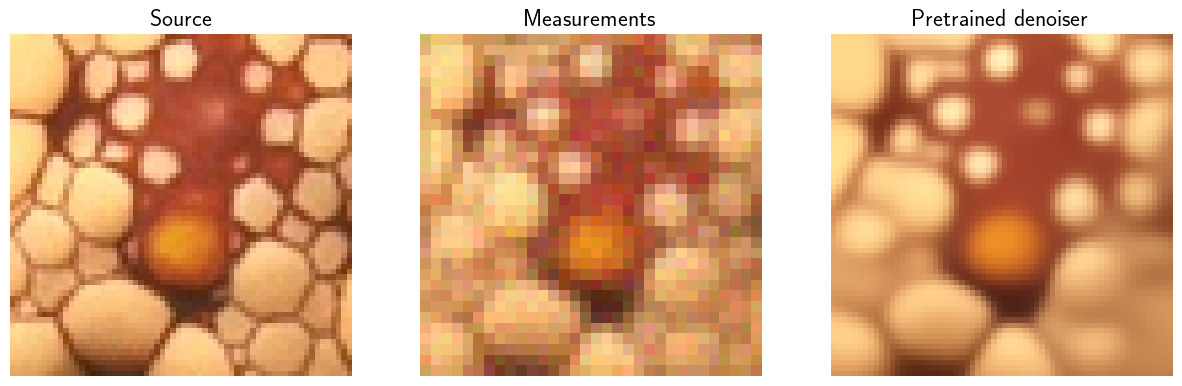

In [13]:
denoiser_pre = dinv.models.GSDRUNet(pretrained = 'download').to(device)
model_pre = prepare_model_PnP(0.05, denoiser_pre)

x_pre = model_pre(
    y, physics, compute_metrics=False, x_gt=x
)

plot_results(x,y,x_pre, 'Pretrained denoiser')

# Find the best denoiser strength sigma

/homes/numerik/melnyk/scratch/anaconda3_new/lib/python3.13/site-packages/deepinv/training/trainer.py:542: UserWarning: Update progress bar frequency of 1 may slow down training on GPU. Consider setting freq_update_progress_bar > 1.
  warnings.warn(
Test: 100%|███████████████████████████████████████████████| 4/4 [00:10<00:00,  2.69s/it, PSNR=17, PSNR no learning=15.9]

Test results:
PSNR no learning: 15.868 +- 0.241
PSNR: 17.021 +- 0.346
Parameter: 0.005  PSNR:  17.02139377593994



Test: 100%|█████████████████████████████████████████████| 4/4 [00:10<00:00,  2.63s/it, PSNR=23.6, PSNR no learning=15.9]

Test results:
PSNR no learning: 15.868 +- 0.241
PSNR: 23.558 +- 1.511
Parameter: 0.01  PSNR:  23.557873725891113



Test: 100%|█████████████████████████████████████████████| 4/4 [00:10<00:00,  2.61s/it, PSNR=23.8, PSNR no learning=15.9]

...


Test: 100%|█████████████████████████████████████████████| 4/4 [00:06<00:00,  1.64s/it, PSNR=22.4, PSNR no learning=15.9]

Test results:
PSNR no learning: 15.868 +- 0.241
PSNR: 22.431 +- 1.981
Parameter: 0.045  PSNR:  22.430707931518555



Test: 100%|█████████████████████████████████████████████| 4/4 [00:05<00:00,  1.34s/it, PSNR=22.2, PSNR no learning=15.9]

Test results:
PSNR no learning: 15.868 +- 0.241
PSNR: 22.239 +- 1.926
Parameter: 0.049999999999999996  PSNR:  22.238905906677246



Test:  67%|██████████████████████████████               | 2/3 [00:07<00:02,  2.34s/it, PSNR=26.1, PSNR no learning=16.2]

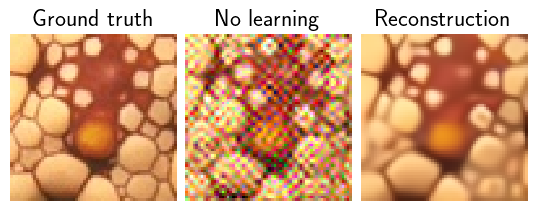

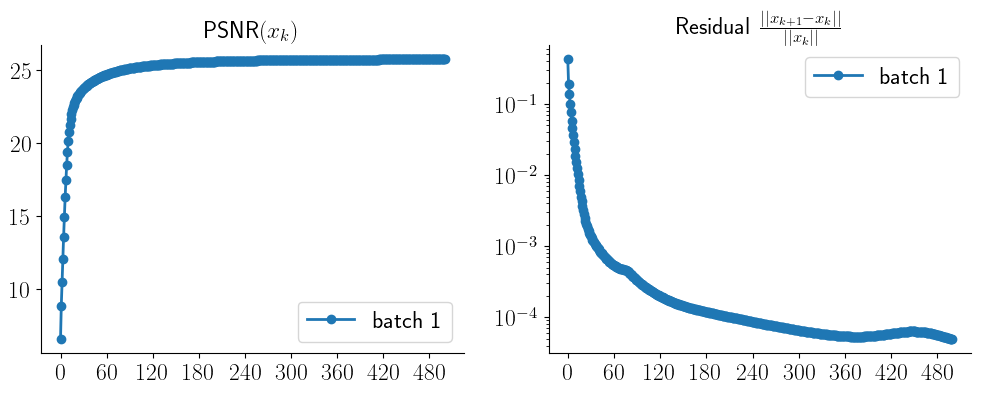

Test: 100%|█████████████████████████████████████████████| 3/3 [00:11<00:00,  3.75s/it, PSNR=26.1, PSNR no learning=16.2]

Test results:
PSNR no learning: 16.164 +- 0.215
PSNR: 26.076 +- 0.585
Best: Paramereter:  0.015 Test PSNR:  26.07579167683919


In [14]:
model_func = lambda sigma: prepare_model_PnP(sigma, denoiser_pre)
model_pre, reg_pre_best, pre_psnr = param_search('Pretrained', model_func, np.arange(0.005,0.051,0.005))

# Our denoiser
In Exercise 5.4.2 we trained a simple UNet-based denoiser. Let use it for PnP-ADMM as well. Unlike GSDRUNet, it had no flexibility for varying $\sigma$. A common solution is to train different models for various values of $\sigma$. We follow a simpler route and decrease the effect of the denoiser as 
$$
D_{t} (x) = (1-t) x + t D(x) = x + t (D(x) - x)
$$

In [15]:
class scaled_denoiser(dinv.models.Denoiser):
    def __init__(self, denoiser):
        super().__init__()
        self.denoiser = denoiser

    def forward(self, x: torch.Tensor, t: float | torch.Tensor) -> torch.Tensor:
        Dg = self.denoiser(x)
        x_hat = (1 - t)*x + t*Dg
        return x_hat

To load our pretrained model, we can use functionality of `torch.load` and checkpoints that Trainer class stores during the training.
In particuler, the model we trained in Exerecise 5.4.2 was stored in `BASE_DIR / 'ckpts' / 'denoising' / TIMESTAMT / 'ckp_best.pth.tar'`. 
Replicate the UNet architecture we used previously and load its parameters via `load_state_dict` function.

Note that we trained our model for $128 \times 128$ patches. Since UNet is based on convolution layers, these are input size invariant, as long as it is large enough to perform the downsampling. Hence, we can use this model for our $64 \times 64$ patches in this exercise. 

In [16]:
denoiser = dinv.models.UNet(
    in_channels=3, out_channels=3, scales=3, batch_norm=False
).to(device)

checkpoint = torch.load(BASE_DIR / 'ckpts' / 'denoising' / '26-01-11-20:28:12' / 'ckp_best.pth.tar', map_location=device, weights_only=True)
denoiser.load_state_dict(checkpoint["state_dict"], strict=True)

<All keys matched successfully>

Test the implementation or scaled denoiser with our model.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.06782916..1.0522804].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.075919576..1.0862153].


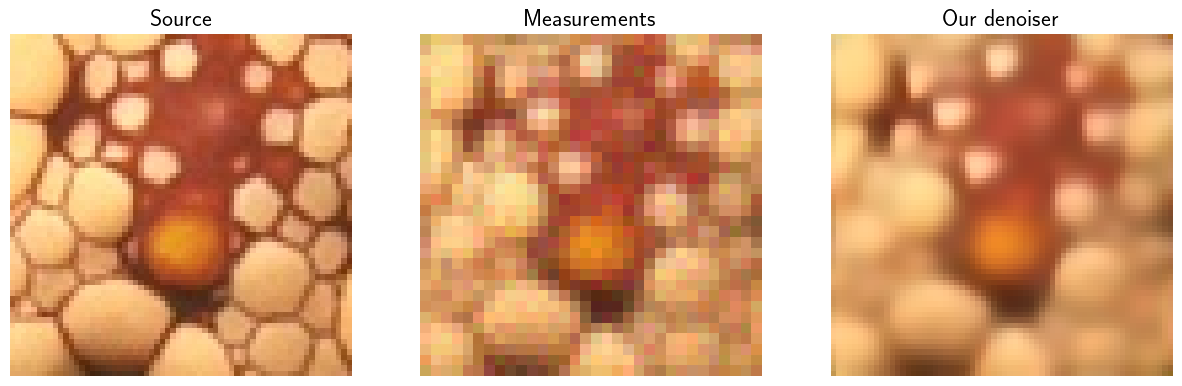

In [17]:
sc_denoiser = scaled_denoiser(denoiser)
model_our = prepare_model_PnP(0.5, sc_denoiser)

x_our = model_our(
    y, physics, compute_metrics=False, x_gt=x
)

plot_results(x,y,x_our, 'Our denoiser')

# Find the best scaling parameter $t$.

In [ ]:
model_func_our = lambda t: prepare_model_PnP(t, sc_denoiser)
model_our, reg_our_best, our_psnr = param_search('Ours', model_func_our, np.arange(0.5,1.01,0.1))

# Summarize the results

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.08743358..1.0464826].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.03933689..1.0629675].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.038831066..1.2059596].


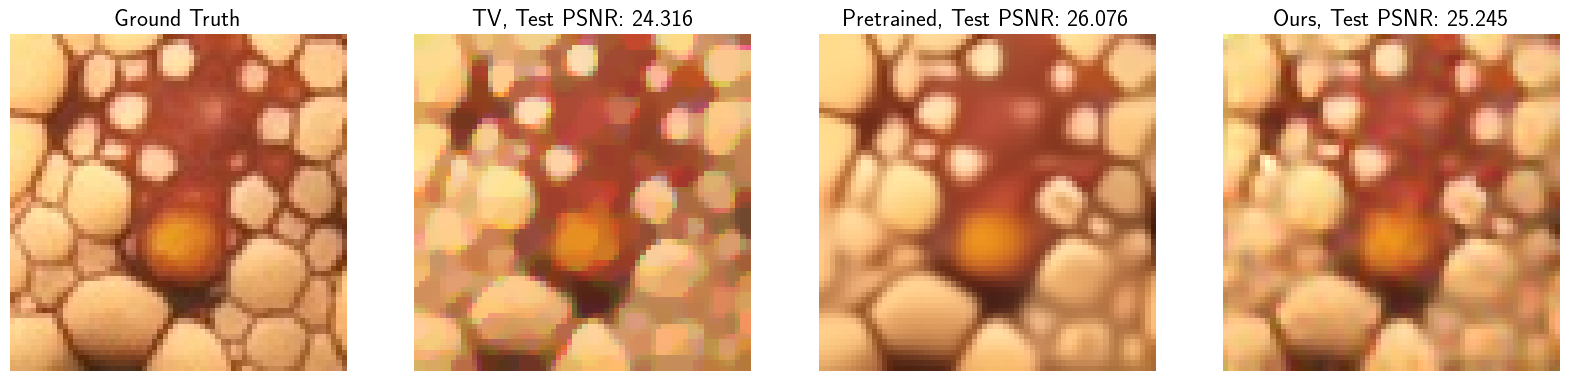

In [19]:
x_tv = model_tv(y,physics)
x_pre = model_pre(y,physics)
x_our = model_our(y,physics)

plt.subplots(1, 4, figsize=(20, 5))
plt.subplot(1, 4, 1)
plt.imshow(x.cpu().permute(1, 2, 0))
plt.axis("off")
plt.title('Ground Truth')

plt.subplot(1, 4, 2)
plt.imshow(x_tv[0].cpu().permute(1, 2, 0))
plt.axis("off")
plt.title(f'TV, Test PSNR: {tv_psnr :.3f}')

plt.subplot(1, 4, 3)
plt.imshow(x_pre[0].cpu().permute(1, 2, 0))
plt.axis("off")
plt.title(f'Pretrained, Test PSNR: {pre_psnr:.3f}')

plt.subplot(1, 4, 4)
plt.imshow(x_our[0].cpu().permute(1, 2, 0))
plt.axis("off")
plt.title(f'Ours, Test PSNR: {our_psnr:.3f}')

plt.show()